# UrbanPulse AI — Model Explainability

## Interpreting Air Pollution Forecasts

**Project:** UrbanPulse AI  
**Dataset:** UCI Beijing Multi-Site Air Quality  
**Primary station:** Aotizhongxin  
**Forecast horizon:** One hour ahead  
**Experiment stage:** Milestone 7 — Explainability

### 7.1 Research Objective

This notebook examines the existing forecasting results to understand which input features are most influential, how model errors vary across pollution levels, and where predictions may be less reliable.

The analysis reuses previously generated model artifacts and evaluation reports from the deep-learning and spatial-modeling experiments. It does not retrain the forecasting models.

Feature importance will be interpreted as a measure of model dependence, not evidence of causation. Results will also be considered in the context of correlated environmental variables, temporal dependencies, and the limitations of the dataset.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(r"C:\UrbanPulse-AI")
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"

assert PROJECT_ROOT.exists(), (
    f"Project folder not found: {PROJECT_ROOT}"
)
assert REPORTS_DIR.exists(), (
    f"Reports folder not found: {REPORTS_DIR}"
)

print("Project root:", PROJECT_ROOT)
print("Reports folder:", REPORTS_DIR)
print("Models folder exists:", MODELS_DIR.exists())

Project root: C:\UrbanPulse-AI
Reports folder: C:\UrbanPulse-AI\reports
Models folder exists: True


In [2]:
artifact_paths = {
    "LSTM test metrics": REPORTS_DIR / "lstm_test_metrics.json",
    "LSTM permutation importance": (
        REPORTS_DIR / "lstm_permutation_feature_importance.csv"
    ),
    "Spatial model metrics": (
        REPORTS_DIR / "spatial_forecasting_metrics.csv"
    ),
    "Spatial feature importance": (
        REPORTS_DIR / "spatial_station_feature_importance.csv"
    ),
    "Spatial permutation importance": (
        REPORTS_DIR / "spatial_test_permutation_importance.csv"
    ),
    "Spatial test diagnostics": (
        REPORTS_DIR / "spatial_test_predictions_diagnostics.csv"
    ),
    "Spatial diagnostic metrics": (
        REPORTS_DIR / "spatial_test_diagnostic_metrics.csv"
    ),
    "Performance by pollution level": (
        REPORTS_DIR / "spatial_test_metrics_by_pollution_level.csv"
    ),
    "Monthly performance": (
        REPORTS_DIR / "spatial_test_monthly_metrics.csv"
    ),
}

artifact_status = pd.DataFrame([
    {
        "Artifact": name,
        "Exists": path.exists(),
        "Size (KB)": (
            round(path.stat().st_size / 1024, 2)
            if path.exists() else None
        ),
        "Path": str(path),
    }
    for name, path in artifact_paths.items()
])

display(artifact_status)

,Artifact,Exists,Size (KB),Path
0,LSTM test metrics,True,0.70,C:\UrbanPulse-AI\reports\lstm_test_metrics.json
1,LSTM permutation importance,True,0.94,C:\UrbanPulse-AI\reports\lstm_permutation_feat...
2,Spatial model metrics,True,0.49,C:\UrbanPulse-AI\reports\spatial_forecasting_m...
3,Spatial feature importance,True,0.39,C:\UrbanPulse-AI\reports\spatial_station_featu...
4,Spatial permutation importance,True,1.18,C:\UrbanPulse-AI\reports\spatial_test_permutat...
5,Spatial test diagnostics,True,517.93,C:\UrbanPulse-AI\reports\spatial_test_predicti...
6,Spatial diagnostic metrics,True,0.30,C:\UrbanPulse-AI\reports\spatial_test_diagnost...
7,Performance by pollution level,True,0.40,C:\UrbanPulse-AI\reports\spatial_test_metrics_...
8,Monthly performance,True,0.58,C:\UrbanPulse-AI\reports\spatial_test_monthly_...


In [3]:
reports = {}

for name, path in artifact_paths.items():
    if not path.exists():
        print(f"NOT FOUND: {name}")
        continue

    try:
        if path.suffix.lower() == ".csv":
            reports[name] = pd.read_csv(path)
            print(f"\n{name}")
            print("Shape:", reports[name].shape)
            print("Columns:", reports[name].columns.tolist())
            display(reports[name].head(3))

        elif path.suffix.lower() == ".json":
            with path.open("r", encoding="utf-8") as file:
                reports[name] = json.load(file)

            print(f"\n{name}")
            print(json.dumps(reports[name], indent=2))

    except Exception as error:
        print(f"Could not load {name}: {error}")


LSTM test metrics
{
  "experiment": "UrbanPulse AI LSTM one-hour-ahead PM2.5",
  "station": "Aotizhongxin",
  "lookback_hours": 24,
  "forecast_horizon_hours": 1,
  "input_features": [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
  ],
  "best_validation_epoch": 17,
  "common_test_observations": 5139,
  "persistence": {
    "mae": 11.027242654212882,
    "rmse": 20.9234606247269,
    "r2": 0.9500286265151131
  },
  "lstm": {
    "mae": 11.451908906579227,
    "rmse": 20.25569409688352,
    "r2": 0.9531673736406041
  },
  "improvement_percent": {
    "mae": -3.851064728353503,
    "rmse": 3.191472671849645
  }
}

LSTM permutation importance
Shape: (11, 5)
Columns: ['Feature', 'Baseline_RMSE', 'Mean_Permuted_RMSE', 'RMSE_Increase', 'Repeat_RMSE_Std']


,Feature,Baseline_RMSE,Mean_Permuted_RMSE,RMSE_Increase,Repeat_RMSE_Std
0,PM2.5,19.874102,97.341925,77.467824,0.671403
1,PM10,19.874102,26.046885,6.172783,0.142491
2,DEWP,19.874102,24.873803,4.999701,0.112341



Spatial model metrics
Shape: (6, 5)
Columns: ['Partition', 'Model', 'MAE', 'RMSE', 'R2']


,Partition,Model,MAE,RMSE,R2
0,Validation,Persistence,10.182103,20.598866,0.940964
1,Validation,Target-only RF,10.400128,20.555904,0.941210
2,Validation,Multi-station RF,9.884780,19.525974,0.946954



Spatial feature importance
Shape: (12, 2)
Columns: ['Station', 'Importance']


...

,Model,MAE,RMSE,R2,Mean_Residual
0,Persistence,11.027243,20.923461,0.950029,0.009924
1,Target-only RF,11.419711,21.193275,0.948732,0.258246
2,Multi-station RF,10.707180,19.607173,0.956118,-0.809723



Performance by pollution level
Shape: (5, 5)
Columns: ['Actual_PM25_Group', 'Observations', 'MAE', 'RMSE', 'Mean_Residual']


,Actual_PM25_Group,Observations,MAE,RMSE,Mean_Residual
0,≤35,2063,5.678802,12.189506,-3.582565
1,>35–75,1000,8.878343,14.717332,-3.814941
2,>75–150,1067,12.409501,20.006974,-0.296899



Monthly performance
Shape: (8, 5)
Columns: ['Month', 'Observations', 'MAE', 'RMSE', 'Mean_Residual']


,Month,Observations,MAE,RMSE,Mean_Residual
0,2016-07,140,10.677273,16.610952,-2.812788
1,2016-08,732,6.667223,10.179955,-2.249146
2,2016-09,690,7.254860,12.031956,-1.707590


## 7.2 Verification of Existing Experimental Artifacts

The explainability analysis reuses saved evaluation reports from the LSTM forecasting experiment and the spatial Random Forest experiment. These reports contain test metrics, feature-importance estimates, prediction diagnostics, pollution-level performance, and monthly evaluation results.

The artifacts were checked for existence and successfully loaded. This notebook does not retrain the forecasting models. Analyses are based on the saved results, with conclusions limited to what those results support.

In [4]:
# Notebook 07 — Section 7.3: Test performance comparison

lstm_metrics = reports["LSTM test metrics"]
spatial_diag = reports["Spatial diagnostic metrics"].copy()

comparison_rows = [
    {
        "Experiment": "LSTM forecasting",
        "Model": "Persistence",
        "MAE": lstm_metrics["persistence"]["mae"],
        "RMSE": lstm_metrics["persistence"]["rmse"],
        "R2": lstm_metrics["persistence"]["r2"],
    },
    {
        "Experiment": "LSTM forecasting",
        "Model": "LSTM",
        "MAE": lstm_metrics["lstm"]["mae"],
        "RMSE": lstm_metrics["lstm"]["rmse"],
        "R2": lstm_metrics["lstm"]["r2"],
    },
]

for _, row in spatial_diag.iterrows():
    comparison_rows.append({
        "Experiment": "Spatial forecasting",
        "Model": row["Model"],
        "MAE": row["MAE"],
        "RMSE": row["RMSE"],
        "R2": row["R2"],
    })

test_comparison = pd.DataFrame(comparison_rows)

# Calculate improvements against the corresponding experiment baseline.
test_comparison["RMSE_Improvement_vs_Baseline_%"] = np.nan
test_comparison["MAE_Improvement_vs_Baseline_%"] = np.nan

for experiment, group in test_comparison.groupby("Experiment"):
    baseline = group.loc[group["Model"] == "Persistence"]

    if baseline.empty:
        continue

    baseline_mae = baseline["MAE"].iloc[0]
    baseline_rmse = baseline["RMSE"].iloc[0]

    for idx in group.index:
        test_comparison.loc[idx, "RMSE_Improvement_vs_Baseline_%"] = (
            (baseline_rmse - test_comparison.loc[idx, "RMSE"])
            / baseline_rmse * 100
        )
        test_comparison.loc[idx, "MAE_Improvement_vs_Baseline_%"] = (
            (baseline_mae - test_comparison.loc[idx, "MAE"])
            / baseline_mae * 100
        )

display(
    test_comparison.round(4)
    .sort_values(["Experiment", "RMSE"])
    .reset_index(drop=True)
)

,Experiment,Model,MAE,RMSE,R2,RMSE_Improvement_vs_Baseline_%,MAE_Improvement_vs_Baseline_%
0,LSTM forecasting,LSTM,11.4519,20.2557,0.9532,3.1915,-3.8511
1,LSTM forecasting,Persistence,11.0272,20.9235,0.9500,0.0000,0.0000
2,Spatial forecasting,Multi-station RF,10.7072,19.6072,0.9561,6.2910,2.9025
3,Spatial forecasting,Persistence,11.0272,20.9235,0.9500,0.0000,0.0000
4,Spatial forecasting,Target-only RF,11.4197,21.1933,0.9487,-1.2895,-3.5591


## 7.3 Test Performance and Model Reliability

The saved test results show different strengths across the forecasting approaches.

In the LSTM experiment, the model achieved a lower RMSE than persistence but a higher MAE. This indicates that the LSTM reduced the influence of larger prediction errors on squared-error performance, but did not improve average absolute error.

In the spatial forecasting experiment, the multi-station Random Forest outperformed both persistence and the target-only Random Forest on test MAE and RMSE. This supports the usefulness of incorporating measurements from multiple monitoring stations in this experiment.

These results should not be interpreted as a definitive ranking of LSTM against Random Forest because the experiments use different feature representations and modeling approaches. Any direct comparison should first confirm that the evaluated timestamps and target observations are identical.

LSTM validation permutation importance
Number of features: 11
Baseline RMSE values: [19.87410173]


,Feature,Baseline_RMSE,Mean_Permuted_RMSE,RMSE_Increase,Repeat_RMSE_Std
0,PM2.5,19.8741,97.3419,77.4678,0.6714
1,PM10,19.8741,26.0469,6.1728,0.1425
2,DEWP,19.8741,24.8738,4.9997,0.1123
3,TEMP,19.8741,23.9141,4.0400,0.0672
4,CO,19.8741,21.4432,1.5691,0.0785
5,NO2,19.8741,20.8833,1.0092,0.0172
6,WSPM,19.8741,20.7996,0.9255,0.1195
7,O3,19.8741,20.5376,0.6635,0.0419
8,RAIN,19.8741,20.1736,0.2995,0.1058
9,SO2,19.8741,20.1367,0.2626,0.0568


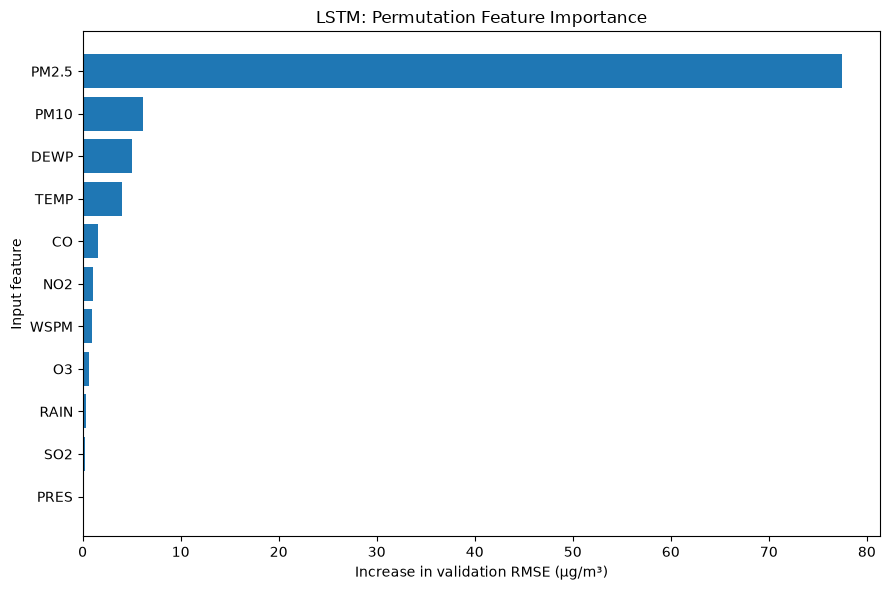

In [5]:
# Notebook 07 — Section 7.4: LSTM feature importance

lstm_importance = (
    reports["LSTM permutation importance"]
    .copy()
    .sort_values("RMSE_Increase", ascending=False)
    .reset_index(drop=True)
)

baseline_values = lstm_importance["Baseline_RMSE"].dropna().unique()

print("LSTM validation permutation importance")
print("Number of features:", len(lstm_importance))
print("Baseline RMSE values:", baseline_values)

display(lstm_importance.round(4))

# Plot the increase in validation RMSE after permutation.
import matplotlib.pyplot as plt

plot_data = lstm_importance.sort_values("RMSE_Increase")

plt.figure(figsize=(9, 6))
plt.barh(plot_data["Feature"], plot_data["RMSE_Increase"])
plt.xlabel("Increase in validation RMSE (µg/m³)")
plt.ylabel("Input feature")
plt.title("LSTM: Permutation Feature Importance")
plt.tight_layout()
plt.show()

Spatial test-set permutation importance


,Rank,Station,Baseline_Test_RMSE,Mean_RMSE_Increase,Std_RMSE_Increase,Mean_Permuted_RMSE,Repeats,Importance
0,1,Aotizhongxin,19.6072,81.2024,0.7924,100.8096,10,0.9632
1,2,Dingling,19.6072,3.5437,0.2167,23.1509,10,0.0053
2,3,Changping,19.6072,0.8406,0.0495,20.4478,10,0.0029
3,4,Dongsi,19.6072,0.8135,0.0692,20.4207,10,0.0039
4,5,Gucheng,19.6072,0.7949,0.0371,20.4020,10,0.0029
5,6,Shunyi,19.6072,0.7787,0.0448,20.3858,10,0.0041
6,7,Wanliu,19.6072,0.7030,0.0320,20.3101,10,0.0028
7,8,Guanyuan,19.6072,0.5310,0.0452,20.1382,10,0.0033
8,9,Nongzhanguan,19.6072,0.5111,0.0341,20.1183,10,0.0031
9,10,Tiantan,19.6072,0.4692,0.0510,20.0763,10,0.0030


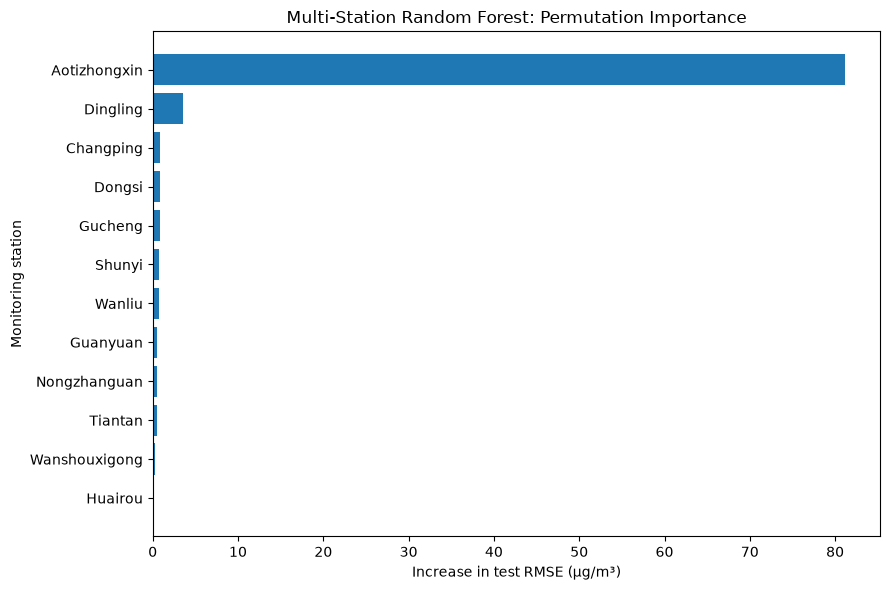

In [6]:
# Notebook 07 — Section 7.5: Spatial station importance

spatial_permutation = (
    reports["Spatial permutation importance"]
    .copy()
    .sort_values("Mean_RMSE_Increase", ascending=False)
    .reset_index(drop=True)
)

spatial_impurity = reports["Spatial feature importance"].copy()

spatial_importance_comparison = spatial_permutation.merge(
    spatial_impurity,
    on="Station",
    how="left",
    validate="one_to_one"
)

print("Spatial test-set permutation importance")
display(spatial_importance_comparison.round(4))

plot_data = spatial_permutation.sort_values("Mean_RMSE_Increase")

plt.figure(figsize=(9, 6))
plt.barh(
    plot_data["Station"],
    plot_data["Mean_RMSE_Increase"]
)
plt.xlabel("Increase in test RMSE (µg/m³)")
plt.ylabel("Monitoring station")
plt.title("Multi-Station Random Forest: Permutation Importance")
plt.tight_layout()
plt.show()

## 7.6 Prediction Error Across Pollution Levels

This section examines whether the multi-station Random Forest's test errors vary across observed PM2.5 concentration groups. The analysis uses the previously saved test metrics grouped by actual pollution level.

The grouped results help identify where forecast errors are larger and whether the model systematically overpredicts or underpredicts. These groups are descriptive evaluation categories, not causal explanations.

,Actual_PM25_Group,Observations,MAE,RMSE,Mean_Residual
0,≤35,2063,5.679,12.190,-3.583
1,>35–75,1000,8.878,14.717,-3.815
2,>75–150,1067,12.410,20.007,-0.297
3,>150–250,679,17.642,26.581,3.997
4,>250,330,27.912,40.664,14.082


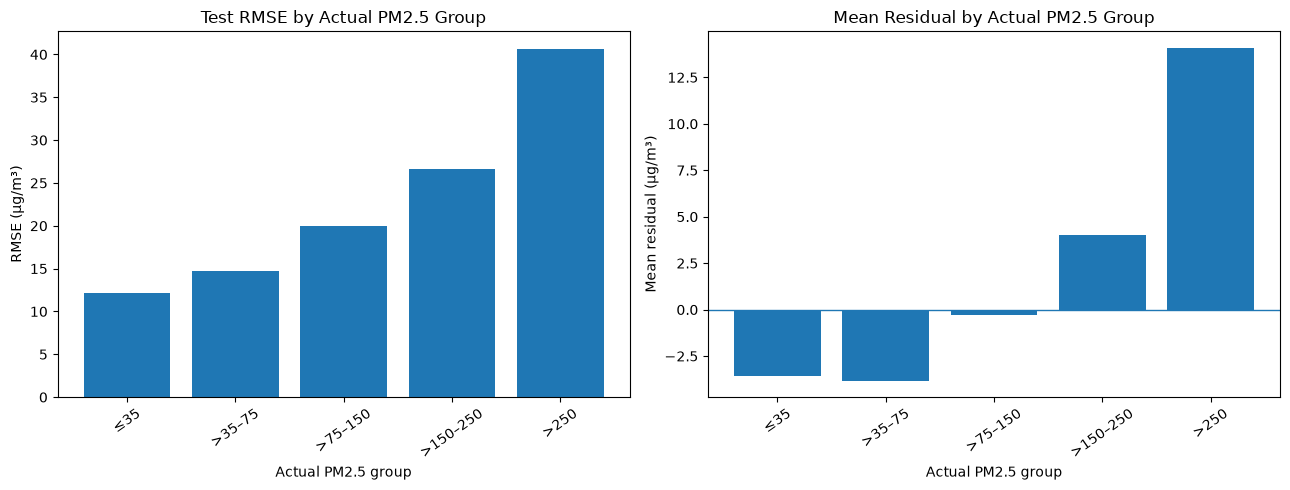

In [7]:
# Notebook 07 — Section 7.6

pollution_performance = (
    reports["Performance by pollution level"]
    .copy()
)

display(pollution_performance.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    pollution_performance["Actual_PM25_Group"].astype(str),
    pollution_performance["RMSE"]
)
axes[0].set_title("Test RMSE by Actual PM2.5 Group")
axes[0].set_xlabel("Actual PM2.5 group")
axes[0].set_ylabel("RMSE (µg/m³)")
axes[0].tick_params(axis="x", rotation=35)

axes[1].bar(
    pollution_performance["Actual_PM25_Group"].astype(str),
    pollution_performance["Mean_Residual"]
)
axes[1].axhline(0, linewidth=1)
axes[1].set_title("Mean Residual by Actual PM2.5 Group")
axes[1].set_xlabel("Actual PM2.5 group")
axes[1].set_ylabel("Mean residual (µg/m³)")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

## 7.7 Temporal Variation in Test Performance

This section evaluates monthly changes in the multi-station Random Forest's test performance. Monthly differences may reflect changes in the distribution of pollution observations, environmental conditions, or the difficulty of forecasting particular periods. The analysis alone cannot determine which factor explains a performance change.

,Month,Observations,MAE,RMSE,Mean_Residual
0,2016-07,140,10.677,16.611,-2.813
1,2016-08,732,6.667,10.180,-2.249
2,2016-09,690,7.255,12.032,-1.708
3,2016-10,735,8.875,14.465,-1.177
4,2016-11,711,12.049,21.011,-0.168
5,2016-12,742,16.163,26.587,1.893
6,2017-01,742,14.290,26.967,-1.345
7,2017-02,647,9.208,18.835,-0.565


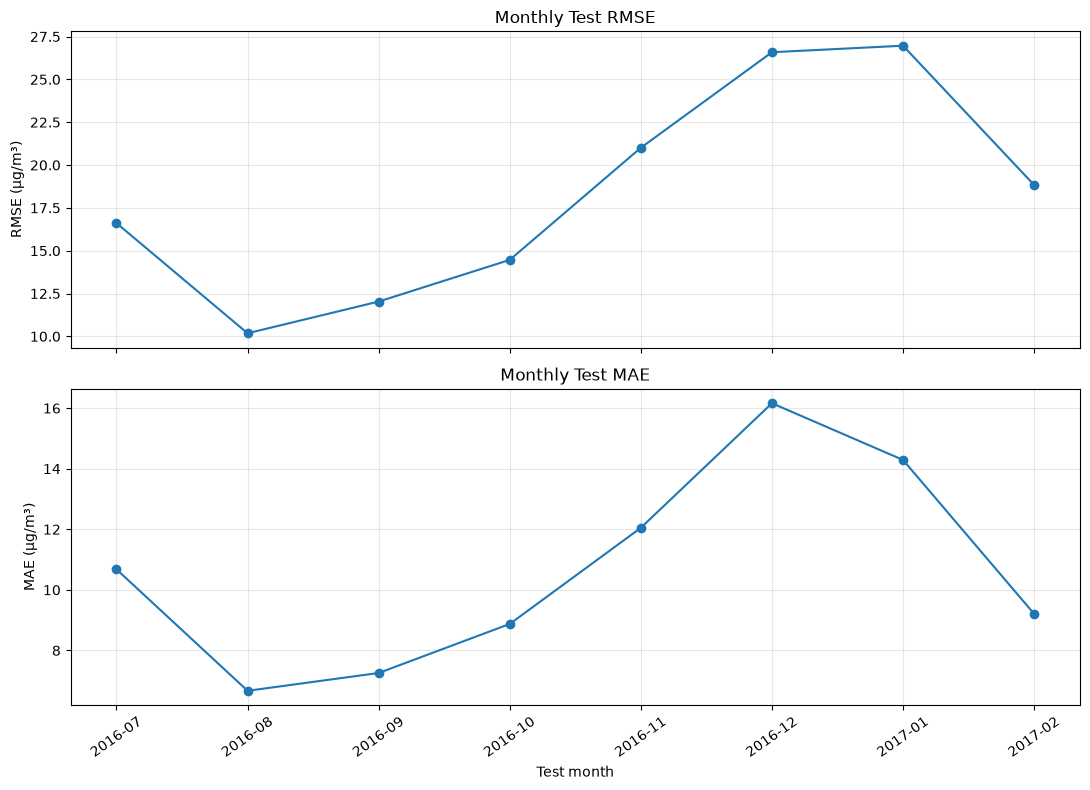

In [8]:
# Notebook 07 — Section 7.7

monthly_performance = (
    reports["Monthly performance"]
    .copy()
)

display(monthly_performance.round(3))

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(
    monthly_performance["Month"].astype(str),
    monthly_performance["RMSE"],
    marker="o"
)
axes[0].set_title("Monthly Test RMSE")
axes[0].set_ylabel("RMSE (µg/m³)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_performance["Month"].astype(str),
    monthly_performance["MAE"],
    marker="o",
    label="MAE"
)
axes[1].set_title("Monthly Test MAE")
axes[1].set_xlabel("Test month")
axes[1].set_ylabel("MAE (µg/m³)")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## 7.8 Limitations of the Explainability Analysis

Several limitations affect the interpretation of these results:

1. **Model dependence is not causation.** Permutation importance measures the change in predictive performance after a feature is shuffled; it does not establish that the feature causes changes in PM2.5.
2. **Correlated predictors complicate interpretation.** When variables contain overlapping information, individually permuting one variable can understate its potential contribution.
3. **Temporal structure matters.** Randomly permuting feature values can disrupt temporal patterns and combinations of observations that occur naturally. The resulting importance values describe the specified permutation procedure.
4. **Different experiments use different input designs.** The LSTM uses 11 pollutant and meteorological features over a 24-hour lookback, while the spatial Random Forest uses contemporaneous station measurements. Their importance values are not directly comparable.
5. **The evidence is geographically limited.** These experiments use the Beijing Multi-Site Air Quality dataset and should not automatically be generalized to other cities or monitoring networks.
6. **Importance rankings do not establish network sufficiency.** Demonstrating that a smaller station network is adequate would require training and evaluating reduced-station models under the same chronological split.

### Conclusion

The LSTM permutation analysis identifies historical PM2.5 as its dominant predictive input, followed by PM10, dew point, and temperature. The spatial Random Forest's test permutation analysis similarly identifies the current Aotizhongxin measurement as its dominant input, with Dingling providing the strongest secondary signal.

The spatial model achieved lower test MAE and RMSE than its persistence and target-only Random Forest baselines. The LSTM reduced test RMSE relative to persistence but did not improve MAE. Error analysis by pollution level and month provides additional information about where model performance varies.

Taken together, these findings provide a descriptive account of model behavior and limitations. They do not establish causal effects or prove that a reduced monitoring network would retain the same forecasting accuracy.